In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [2]:
PROJECT_PATH = '/content/drive/MyDrive/project'

In [3]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 30.1 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Using device: cpu
YOLO and Reader models loaded successfully.
Image: mchar_test_a/031522.png
Predicted: 690


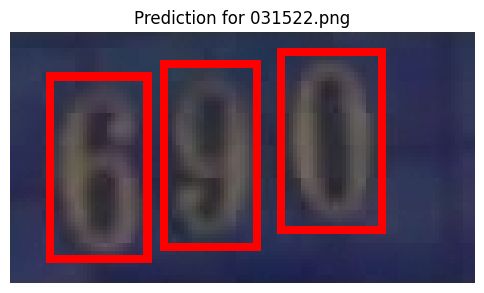

In [4]:
import torch
import os
import random
import zipfile
import io
from PIL import Image, ImageDraw, ImageFont
import sys
import torch.nn as nn
from torchvision import models, transforms
from ultralytics import YOLO

# --- PATH SETUP ---
PROJECT_ROOT = '/content/drive/MyDrive/project'
sys.path.append(os.path.join(PROJECT_ROOT, "code"))

# --- MODEL & TRANSFORMS DEFINITION ---

def get_reader_model():
    """Defines the EfficientNet model structure for single digit classification."""
    model = models.efficientnet_b0(weights=None)
    model.classifier[1] = nn.Linear(1280, 10) # Output 10 classes (0-9)
    return model

reader_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

def show_random_prediction_yolo():
    """
    Selects a random image, predicts using YOLO + Reader, and displays the result.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # --- PATHS ---
    # NOTE: Update YOLO_PATH if you use a different model file.
    yolo_path = os.path.join(PROJECT_ROOT, "runs", "detect", "number_v8", "weights", "best.pt")
    reader_path = os.path.join(PROJECT_ROOT, "user_data", "model_data", "single_digit_best.pth")
    zip_path = os.path.join(PROJECT_ROOT, "tcdata", "mchar_test_a.zip")

    # --- PATH VALIDATION ---
    for path in [yolo_path, reader_path, zip_path]:
        if not os.path.exists(path):
            print(f"Error: File not found at {path}.")
            return

    # --- LOAD MODELS ---
    try:
        yolo_model = YOLO(yolo_path)
        reader_model = get_reader_model().to(device)
        reader_model.load_state_dict(torch.load(reader_path, map_location=device))
        reader_model.eval()
        print("YOLO and Reader models loaded successfully.")
    except Exception as e:
        print(f"Error loading models: {e}")
        return

    # --- LOAD RANDOM IMAGE ---
    with zipfile.ZipFile(zip_path, 'r') as zf:
        image_files = [f for f in zf.namelist() if f.lower().endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('__MACOSX')]
        if not image_files:
            print("No images found in the zip file.")
            return

        random_image_name = random.choice(image_files)
        img_bytes = zf.read(random_image_name)
        original_image = Image.open(io.BytesIO(img_bytes)).convert("RGB")

    # --- PREDICT USING YOLO + READER PIPELINE ---
    pred_str = ""
    detections = []
    draw = ImageDraw.Draw(original_image)

    # 1. YOLO Detection
    yolo_results = yolo_model(original_image, verbose=False, iou=0.35)

    if yolo_results and yolo_results[0].boxes is not None and len(yolo_results[0].boxes) > 0:
        boxes = yolo_results[0].boxes.xyxy.cpu().numpy()

        # 2. Crop and Read each detected box
        for box in boxes:
            x1, y1, x2, y2 = map(int, box)
            draw.rectangle([x1, y1, x2, y2], outline="red", width=2)

            crop = original_image.crop((x1, y1, x2, y2))
            input_tensor = reader_tf(crop).unsqueeze(0).to(device)

            with torch.no_grad():
                output = reader_model(input_tensor)
                _, pred = torch.max(output, 1)
                digit = pred.item()

            detections.append({"digit": digit, "x_center": (x1 + x2) / 2})

    # 3. Sort detections left-to-right and create final string
    if detections:
        detections.sort(key=lambda x: x["x_center"])
        pred_str = "".join(str(d["digit"]) for d in detections)

    print(f"Image: {random_image_name}")
    print(f"Predicted: {pred_str}")

    # --- DISPLAY RESULT ---
    import matplotlib.pyplot as plt

    plt.figure(figsize=(6, 4))
    plt.imshow(original_image)
    plt.axis('off')
    plt.title(f"Prediction for {os.path.basename(random_image_name)}")
    plt.show()

if __name__ == "__main__":
    show_random_prediction_yolo()